# 03 – Resume classification: TF-IDF vs sentence embeddings

Question: does a pre-trained sentence-embedding model (`all-MiniLM-L6-v2`) classify resumes better than the TF-IDF baseline of notebook 02?

Three models, trained and tested on the **same split** (80/20, stratified, duplicates removed):
1. TF-IDF (words + bigrams) + logistic regression – the baseline;
2. embeddings of the first 256 tokens + logistic regression;
3. embeddings of the whole resume (mean of chunks of 150 words) + logistic regression.

In [1]:
import sys
sys.path.insert(0, "..")          # the shared code lives in ../matcher
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score, classification_report

from matcher.data import load_resumes
from matcher.models import split, tfidf_classifier, embed_documents, embedding_classifier
from matcher.embed import get_model

In [2]:
resumes = load_resumes()
X_train, X_test, y_train, y_test = split(resumes)
print(len(X_train), "train /", len(X_test), "test")

# The embedding model reads at most 256 tokens: how many resumes are longer?
tok = get_model().tokenizer
n_tokens = X_test.map(lambda t: len(tok(t)["input_ids"]))
print(f"Median length: {n_tokens.median():.0f} tokens; truncated at 256: {(n_tokens > 256).mean():.0%} of the resumes")

9668 train / 2417 test


Token indices sequence length is longer than the specified maximum sequence length for this model (683 > 256). Running this sequence through the model will result in indexing errors


Median length: 472 tokens; truncated at 256: 86% of the resumes


## 1. TF-IDF baseline

In [3]:
results = {}
t0 = time.time()
tfidf = tfidf_classifier().fit(X_train, y_train)
pred_tfidf = tfidf.predict(X_test)
results["TF-IDF + LR"] = (accuracy_score(y_test, pred_tfidf), f1_score(y_test, pred_tfidf, average="macro"), time.time() - t0)
results["TF-IDF + LR"]

(0.8059577989242863, 0.8061840373028364, 43.538981914520264)

## 2. Sentence embeddings

Encoding takes a few minutes the first time; the vectors are cached in `data/`.

In [4]:
t0 = time.time()
E_train_first = embed_documents(X_train, name="train_first", chunked=False)
E_test_first = embed_documents(X_test, name="test_first", chunked=False)
E_train = embed_documents(X_train, name="train_chunks")
E_test = embed_documents(X_test, name="test_chunks")
print(f"Encoding: {time.time() - t0:.0f} s, vectors of {E_train.shape[1]} dimensions")

Batches:   0%|          | 0/152 [00:00<?, ?it/s]

Batches:   0%|          | 0/38 [00:00<?, ?it/s]

Batches:   0%|          | 0/537 [00:00<?, ?it/s]

Batches:   0%|          | 0/134 [00:00<?, ?it/s]

Encoding: 169 s, vectors of 384 dimensions


In [5]:
for name, (Etr, Ete) in {"Embeddings first 256 tokens + LR": (E_train_first, E_test_first),
                          "Embeddings all chunks + LR": (E_train, E_test)}.items():
    t0 = time.time()
    clf = embedding_classifier().fit(Etr, y_train)
    pred = clf.predict(Ete)
    results[name] = (accuracy_score(y_test, pred), f1_score(y_test, pred, average="macro"), time.time() - t0)
    if "chunks" in name:
        emb_clf, pred_emb = clf, pred

summary = pd.DataFrame(results, index=["accuracy", "macro F1", "training time (s)"]).T.round(3)
summary

,accuracy,macro F1,training time (s)
TF-IDF + LR,0.806,0.806,43.539
Embeddings first 256 tokens + LR,0.732,0.726,0.767
Embeddings all chunks + LR,0.707,0.708,0.772


## 3. Where do the two approaches differ?

In [6]:
f1 = pd.DataFrame({
    "TF-IDF": pd.DataFrame(classification_report(y_test, pred_tfidf, output_dict=True)).T["f1-score"],
    "Embeddings": pd.DataFrame(classification_report(y_test, pred_emb, output_dict=True)).T["f1-score"],
}).iloc[:-3]
f1["difference"] = f1["Embeddings"] - f1["TF-IDF"]
f1.sort_values("difference").round(3).iloc[np.r_[0:6, -6:0]]     # 6 categories where each model wins most

,TF-IDF,Embeddings,difference
Consultant,0.672,0.298,-0.374
Advocate,0.748,0.520,-0.228
Operations Manager,0.754,0.531,-0.222
PMO,0.863,0.653,-0.210
Management,0.412,0.205,-0.207
BPO,0.600,0.394,-0.206
Mechanical Engineer,0.929,0.900,-0.029
Agriculture,0.747,0.727,-0.019
DevOps,0.980,0.970,-0.010
SQL Developer,0.800,0.796,-0.004


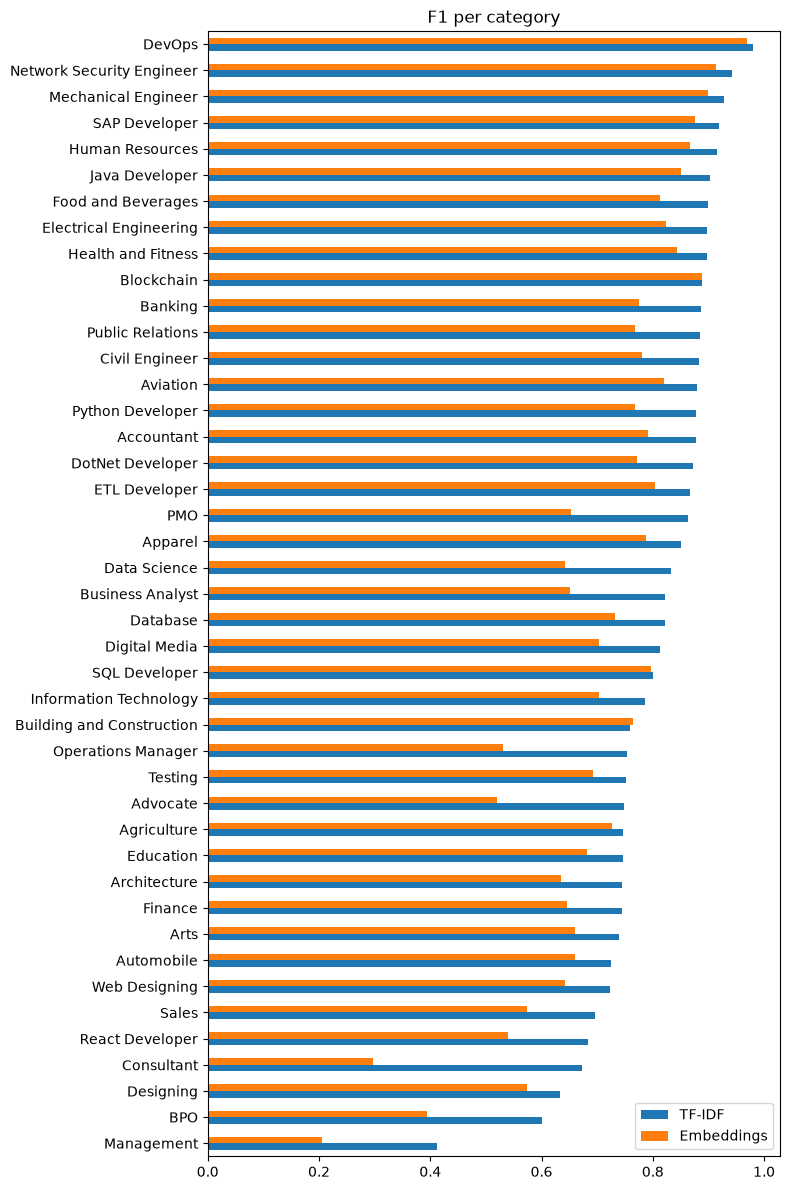

In [7]:
f1.sort_values("TF-IDF")[["TF-IDF", "Embeddings"]].plot.barh(figsize=(8, 12), title="F1 per category")
plt.tight_layout(); plt.show()

In [8]:
# Errors of the best model: are they reasonable confusions?
best_pred = pred_tfidf if results["TF-IDF + LR"][1] >= results["Embeddings all chunks + LR"][1] else pred_emb
err = pd.DataFrame({"true": y_test.values, "pred": best_pred})
err[err["true"] != err["pred"]].value_counts().head(12)

true            pred                     
Management      Advocate                     8
Arts            Education                    6
SQL Developer   Database                     6
Data Science    Education                    6
Sales           Management                   5
Management      Operations Manager           5
Apparel         Sales                        5
Arts            Designing                    5
Database        SQL Developer                4
Automobile      Sales                        4
Finance         Sales                        4
Civil Engineer  Building and Construction    4
Name: count, dtype: int64

In [9]:
# Read a few misclassified resumes
wrong = np.where(y_test.values != best_pred)[0][:3]
for i in wrong:
    print(f"TRUE {y_test.values[i]} / PREDICTED {best_pred[i]}\n{X_test.values[i][:400]}\n")

TRUE Management / PREDICTED Building and Construction
skye havelock construction manager phone 347 9871234 email skyehavelockgmailcom linkedin linkedincominskyehavelock junior construction manager 4 years experience stages residential commercial development 2018 project achievement award recipient ccm certification nycregistered construction management license cut costs 20 5 different building projects seeking continue growth implementing constructio

TRUE Education / PREDICTED Designing
tara terry primary teacher consectetuer adipiscing elit diam nonummy nibh euismod tincidunt ut laoreet dolore magna aliquam erat volutpat ut wisi enim ad minim veniam quis nostrud exerci tation 10234567890 mailexamplecom education work experience 20202022 elementary school teacher pellentesque erat arcu laoreet nec mattis sodales consectetur quam fusce ac mattis metus suspendisse lobortis arcu et 

TRUE Digital Media / PREDICTED Finance
jessica claire montgomery street san francisco ca 94105 555 432100

## Findings

| Model | Accuracy | Macro F1 |
|-------|----------|----------|
| TF-IDF + logistic regression | **0.806** | **0.806** |
| Embeddings (first 256 tokens) + LR | 0.732 | 0.726 |
| Embeddings (mean of chunks) + LR | 0.707 | 0.708 |

- **TF-IDF wins by 8 points.** The category of a resume is decided by a few specific keywords (java, autocad, payroll); TF-IDF keeps them, while a sentence embedding compresses the whole text into 384 numbers and blurs close categories.
- The gap is largest for broad categories: Consultant (-0.37 F1), Advocate, Operations Manager, PMO, Management (-0.21). Embeddings are almost as good on technical categories (DevOps, Mechanical Engineer, SQL Developer).
- **86% of the resumes are longer than the 256 tokens** read by the model (median 472 tokens). Averaging the chunks of the whole resume did *not* help (0.708 < 0.726): the beginning of a resume (title, summary) is the most informative part, and the rest dilutes it.
- Embeddings train in under a second (vs 44 s for TF-IDF), but need 3 minutes of encoding.
- Some errors are template resumes filled with placeholder text ("lorem ipsum"): no model can classify them.
- **Choice for the app: TF-IDF + logistic regression.**